In [1]:
# Install all libraries required for the project

!pip -q install pandas openpyxl pyspark xgboost transformers torch tensorflow scikit-learn seaborn matplotlib

In [2]:
# Import required Python libraries

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
# Upload the supplier risk Excel dataset

uploaded = files.upload()

file_name = next(iter(uploaded))

print("Uploaded file:", file_name)

Saving supplier_risk_10000rows_19columns.xlsx to supplier_risk_10000rows_19columns.xlsx
Uploaded file: supplier_risk_10000rows_19columns.xlsx


In [4]:
# Read Excel dataset using pandas

df = pd.read_excel(file_name)

print("Dataset loaded successfully")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully
Number of rows and columns: (10000, 19)


,Supplier_ID,Supplier_Name,Industry,Country,Date,Revenue_Million_USD,Debt_Million_USD,Assets_Million_USD,Current_Assets_Million_USD,Current_Liabilities_Million_USD,Leverage,Current_Ratio,Financial_Stability_ZScore,Profit_Margin,Cash_Flow_Million_USD,News_Headline,News_Text,Synthetic_News_Sentiment,Disruption_Within_90_Days
0,SUP0045,Supplier_0045,Consumer Goods,Canada,2023-08-24,1317.21,1052.53,2495.97,1155.21,639.32,0.4217,1.8069,0.1802,NaN,30.04,Company announces higher production capacity a...,Company announces higher production capacity a...,Positive,0
1,SUP0119,Supplier_0119,Machinery,Singapore,2023-10-25,1660.04,NaN,4201.69,1521.64,1536.59,0.1302,0.9903,0.3162,0.0338,41.74,Supplier records improved profits and stronger...,Supplier records improved profits and stronger...,Positive,0
2,SUP0088,Supplier_0088,Automotive,UK,2023-09-11,1412.00,792.37,5242.61,1459.39,1337.36,0.1511,1.0912,0.3048,0.1002,156.96,Company secures new contracts and expects stab...,Company secures new contracts and expects stab...,Positive,0
3,SUP0209,Supplier_0209,Consumer Goods,Japan,2023-10-10,1688.16,1327.17,4154.97,1742.23,661.30,0.3194,2.6345,0.4407,-0.0062,88.26,Supplier publishes its regular quarterly busin...,Supplier publishes its regular quarterly busin...,Neutral,0
4,SUP0202,Supplier_0202,Automotive,Germany,2023-01-12,1626.90,1405.88,2093.40,1319.15,1530.80,0.6716,0.8617,-0.2251,0.0484,96.77,Company announces higher production capacity a...,Company announces higher production capacity a...,Positive,0


In [5]:
# Display column names

print("Columns:")
print(df.columns.tolist())

# Display data types

print("\nData Types:")
display(df.dtypes)

# Display number of rows and columns

print("\nDataset Shape:")
print(df.shape)

# Check duplicate records

print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check missing values

print("\nMissing Values:")
display(df.isnull().sum().sort_values(ascending=False))

Columns:
['Supplier_ID', 'Supplier_Name', 'Industry', 'Country', 'Date', 'Revenue_Million_USD', 'Debt_Million_USD', 'Assets_Million_USD', 'Current_Assets_Million_USD', 'Current_Liabilities_Million_USD', 'Leverage', 'Current_Ratio', 'Financial_Stability_ZScore', 'Profit_Margin', 'Cash_Flow_Million_USD', 'News_Headline', 'News_Text', 'Synthetic_News_Sentiment', 'Disruption_Within_90_Days']

Data Types:


,0
Supplier_ID,object
Supplier_Name,object
Industry,object
Country,object
Date,datetime64[ns]
Revenue_Million_USD,float64
Debt_Million_USD,float64
Assets_Million_USD,float64
Current_Assets_Million_USD,float64
Current_Liabilities_Million_USD,float64



Dataset Shape:
(10000, 19)

Duplicate Rows:
20

Missing Values:


,0
Cash_Flow_Million_USD,120
Current_Ratio,120
Revenue_Million_USD,120
Financial_Stability_ZScore,119
Debt_Million_USD,119
Profit_Margin,118
Supplier_ID,0
Industry,0
Supplier_Name,0
Date,0


In [6]:
# Convert Date column into proper date format

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Count rows before removing duplicates

before = len(df)

# Remove duplicate rows

df = df.drop_duplicates().reset_index(drop=True)

# Count rows after removing duplicates

after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)

Rows before removing duplicates: 10000
Rows after removing duplicates: 9980
Duplicates removed: 20


In [7]:
# Financial columns used by XGBoost

financial_cols = [
    "Revenue_Million_USD",
    "Debt_Million_USD",
    "Assets_Million_USD",
    "Current_Assets_Million_USD",
    "Current_Liabilities_Million_USD",
    "Leverage",
    "Current_Ratio",
    "Financial_Stability_ZScore",
    "Profit_Margin",
    "Cash_Flow_Million_USD"
]

# Categorical columns

categorical_cols = [
    "Industry",
    "Country"
]

# News/text columns

text_cols = [
    "News_Headline",
    "News_Text"
]

# Prediction target

target_col = "Disruption_Within_90_Days"

print("Financial columns:", len(financial_cols))
print("Categorical columns:", categorical_cols)
print("Text columns:", text_cols)
print("Target column:", target_col)

Financial columns: 10
Categorical columns: ['Industry', 'Country']
Text columns: ['News_Headline', 'News_Text']
Target column: Disruption_Within_90_Days


In [8]:
# Convert financial columns into numeric values

for col in financial_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

    # Replace missing values with median

    df[col] = df[col].fillna(
        df[col].median()
    )

# Convert target into integer

df[target_col] = pd.to_numeric(
    df[target_col],
    errors="coerce"
).fillna(0).astype(int)

print("Missing values after cleaning:")

display(
    df[financial_cols].isnull().sum()
)

Missing values after cleaning:


,0
Revenue_Million_USD,0
Debt_Million_USD,0
Assets_Million_USD,0
Current_Assets_Million_USD,0
Current_Liabilities_Million_USD,0
Leverage,0
Current_Ratio,0
Financial_Stability_ZScore,0
Profit_Margin,0
Cash_Flow_Million_USD,0


In [9]:
# Replace missing categorical values

for col in categorical_cols:

    df[col] = df[col].fillna(
        "Unknown"
    ).astype(str)

# Replace missing text values

for col in text_cols:

    df[col] = df[col].fillna(
        "Unknown"
    ).astype(str)

# Combine headline and news text
# This combined text will be given to FinBERT

df["News_Combined"] = (
    df["News_Headline"].str.strip()
    + ". "
    + df["News_Text"].str.strip()
)

display(
    df[
        [
            "News_Headline",
            "News_Text",
            "News_Combined"
        ]
    ].head()
)

,News_Headline,News_Text,News_Combined
0,Company announces higher production capacity a...,Company announces higher production capacity a...,Company announces higher production capacity a...
1,Supplier records improved profits and stronger...,Supplier records improved profits and stronger...,Supplier records improved profits and stronger...
2,Company secures new contracts and expects stab...,Company secures new contracts and expects stab...,Company secures new contracts and expects stab...
3,Supplier publishes its regular quarterly busin...,Supplier publishes its regular quarterly busin...,Supplier publishes its regular quarterly busin...
4,Company announces higher production capacity a...,Company announces higher production capacity a...,Company announces higher production capacity a...


Target Distribution:


,count
Disruption_Within_90_Days,
0,9600
1,380



Target Percentage:


,proportion
Disruption_Within_90_Days,
0,96.19
1,3.81


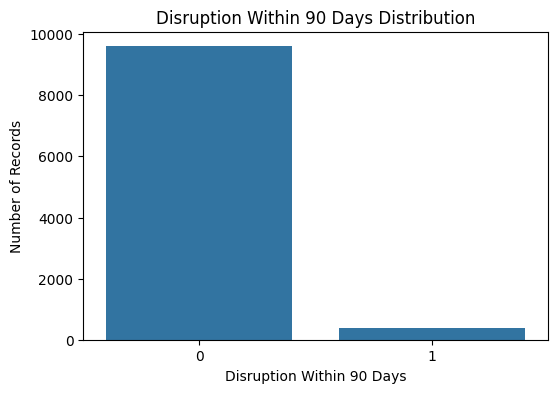

In [10]:
# Display number of disruption and non-disruption records

print("Target Distribution:")

display(
    df[target_col].value_counts()
)

# Display percentages

print("\nTarget Percentage:")

display(
    (
        df[target_col]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)

# Plot target distribution

plt.figure(figsize=(6,4))

sns.countplot(
    x=target_col,
    data=df
)

plt.title(
    "Disruption Within 90 Days Distribution"
)

plt.xlabel(
    "Disruption Within 90 Days"
)

plt.ylabel(
    "Number of Records"
)

plt.show()

In [11]:
# Import PySpark

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Create Spark session

spark = (
    SparkSession.builder
    .appName("SupplierRiskPreprocessing")
    .master("local[*]")
    .getOrCreate()
)

print("Spark started successfully")

Spark started successfully


In [12]:
# Convert cleaned pandas dataframe to Spark dataframe

spark_df = spark.createDataFrame(df)

print(
    "Number of Spark rows:",
    spark_df.count()
)

print(
    "Number of Spark columns:",
    len(spark_df.columns)
)

# Display schema

spark_df.printSchema()

Number of Spark rows: 9980
Number of Spark columns: 20
root
 |-- Supplier_ID: string (nullable = true)
 |-- Supplier_Name: string (nullable = true)
 |-- Industry: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Date: timestamp (nullable = true)
 |-- Revenue_Million_USD: double (nullable = true)
 |-- Debt_Million_USD: double (nullable = true)
 |-- Assets_Million_USD: double (nullable = true)
 |-- Current_Assets_Million_USD: double (nullable = true)
 |-- Current_Liabilities_Million_USD: double (nullable = true)
 |-- Leverage: double (nullable = true)
 |-- Current_Ratio: double (nullable = true)
 |-- Financial_Stability_ZScore: double (nullable = true)
 |-- Profit_Margin: double (nullable = true)
 |-- Cash_Flow_Million_USD: double (nullable = true)
 |-- News_Headline: string (nullable = true)
 |-- News_Text: string (nullable = true)
 |-- Synthetic_News_Sentiment: string (nullable = true)
 |-- Disruption_Within_90_Days: long (nullable = true)
 |-- News_Combined: string

In [13]:
# Remove duplicate records using Spark

spark_df = spark_df.dropDuplicates()

# Sort by Supplier ID and Date

spark_df = spark_df.orderBy(
    "Supplier_ID",
    "Date"
)

print("PySpark preprocessing completed")

PySpark preprocessing completed


In [14]:
# Create a new financial stress feature.
#
# Higher leverage can increase financial stress.
# Lower current ratio can also indicate financial pressure.

spark_df = spark_df.withColumn(
    "Financial_Stress_Index",
    (
        F.coalesce(
            F.col("Leverage"),
            F.lit(0)
        )
        +
        (
            F.lit(1) /
            F.greatest(
                F.coalesce(
                    F.col("Current_Ratio"),
                    F.lit(1)
                ),
                F.lit(0.1)
            )
        )
    )
)

display(
    spark_df.select(
        "Supplier_ID",
        "Date",
        "Leverage",
        "Current_Ratio",
        "Financial_Stress_Index"
    ).limit(10).toPandas()
)

,Supplier_ID,Date,Leverage,Current_Ratio,Financial_Stress_Index
0,SUP0001,2023-01-04,0.3041,2.0967,0.781040
1,SUP0001,2023-01-11,0.3695,2.6843,0.742037
2,SUP0001,2023-01-22,0.2590,0.6503,1.796752
3,SUP0001,2023-01-29,0.2725,1.8789,0.804726
4,SUP0001,2023-02-06,0.4577,0.8651,1.613636
5,SUP0001,2023-02-15,0.2224,1.9975,0.723026
6,SUP0001,2023-02-28,0.3084,1.1022,1.215676
7,SUP0001,2023-03-08,0.2867,0.9496,1.339775
8,SUP0001,2023-03-17,0.3183,1.3934,1.035969
9,SUP0001,2023-03-26,0.4295,1.2737,1.214614


In [15]:
# Convert Spark dataframe back to Pandas
# because XGBoost, FinBERT and TensorFlow
# will be used next.

df = spark_df.toPandas()

df["Date"] = pd.to_datetime(
    df["Date"]
)

df = df.sort_values(
    ["Date", "Supplier_ID"]
).reset_index(drop=True)

print(
    "Final preprocessing shape:",
    df.shape
)

Final preprocessing shape: (9980, 21)


In [16]:
# Import machine learning utilities

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

# XGBoost features

xgb_features = (
    financial_cols
    + ["Financial_Stress_Index"]
)

# Sort dataset by date

df_sorted = df.sort_values(
    "Date"
).reset_index(drop=True)

# 80% data for training

split_index = int(
    len(df_sorted) * 0.80
)

train_df = df_sorted.iloc[
    :split_index
].copy()

test_df = df_sorted.iloc[
    split_index:
].copy()

X_train = train_df[
    xgb_features
]

y_train = train_df[
    target_col
]

X_test = test_df[
    xgb_features
]

y_test = test_df[
    target_col
]

# Handle remaining missing values

imputer = SimpleImputer(
    strategy="median"
)

X_train = imputer.fit_transform(
    X_train
)

X_test = imputer.transform(
    X_test
)

print(
    "Training rows:",
    len(X_train)
)

print(
    "Testing rows:",
    len(X_test)
)

Training rows: 7984
Testing rows: 1996


In [17]:
# Calculate class imbalance

negative_count = max(
    (y_train == 0).sum(),
    1
)

positive_count = max(
    (y_train == 1).sum(),
    1
)

scale_pos_weight = (
    negative_count /
    positive_count
)

# Create XGBoost model

xgb_model = XGBClassifier(

    n_estimators=250,

    max_depth=5,

    learning_rate=0.05,

    subsample=0.85,

    colsample_bytree=0.85,

    objective="binary:logistic",

    eval_metric="logloss",

    scale_pos_weight=scale_pos_weight,

    random_state=42
)

# Train model

xgb_model.fit(
    X_train,
    y_train
)

print(
    "XGBoost training completed"
)

XGBoost training completed


In [18]:
# Predict probability of disruption

xgb_probability = (
    xgb_model
    .predict_proba(X_test)[:, 1]
)

# Convert probability into class

xgb_prediction = (
    xgb_probability >= 0.50
).astype(int)

print(
    classification_report(
        y_test,
        xgb_prediction,
        zero_division=0
    )
)

# Calculate ROC-AUC if both classes exist

if y_test.nunique() == 2:

    print(
        "XGBoost ROC-AUC:",
        round(
            roc_auc_score(
                y_test,
                xgb_probability
            ),
            4
        )
    )

              precision    recall  f1-score   support

           0       0.96      0.93      0.95      1881
           1       0.26      0.40      0.31       115

    accuracy                           0.90      1996
   macro avg       0.61      0.66      0.63      1996
weighted avg       0.92      0.90      0.91      1996

XGBoost ROC-AUC: 0.8347


In [19]:
# Apply the trained XGBoost model
# to the complete processed dataset.

X_all = imputer.transform(
    df[xgb_features]
)

df[
    "XGBoost_Financial_Risk_Probability"
] = (
    xgb_model
    .predict_proba(X_all)[:, 1]
)

display(
    df[
        [
            "Supplier_ID",
            "Date",
            "XGBoost_Financial_Risk_Probability"
        ]
    ].head(10)
)

,Supplier_ID,Date,XGBoost_Financial_Risk_Probability
0,SUP0002,2023-01-01,0.042213
1,SUP0008,2023-01-01,0.002468
2,SUP0009,2023-01-01,0.006617
3,SUP0010,2023-01-01,0.003634
4,SUP0018,2023-01-01,0.003038
5,SUP0022,2023-01-01,0.000547
6,SUP0023,2023-01-01,0.002754
7,SUP0024,2023-01-01,0.986258
8,SUP0032,2023-01-01,0.004166
9,SUP0040,2023-01-01,0.002339


In [20]:
# Import PyTorch and Hugging Face pipeline

import torch

from transformers import pipeline

# Check whether GPU is available

device = (
    0
    if torch.cuda.is_available()
    else -1
)

# Load FinBERT

finbert = pipeline(

    "text-classification",

    model="ProsusAI/finbert",

    tokenizer="ProsusAI/finbert",

    device=device,

    top_k=None
)

print(
    "FinBERT loaded successfully"
)

print(
    "Device:",
    "GPU" if device == 0 else "CPU"
)

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

FinBERT loaded successfully
Device: CPU


In [21]:
# Get all news text

texts = (
    df["News_Combined"]
    .fillna("")
    .astype(str)
    .tolist()
)

# Batch size
# GPU can normally process larger batches.

batch_size = (
    16 if device == 0
    else 8
)

finbert_results = []

# Process news in batches

for start in range(
    0,
    len(texts),
    batch_size
):

    batch = texts[
        start:start + batch_size
    ]

    result = finbert(
        batch,
        truncation=True,
        max_length=256,
        batch_size=batch_size
    )

    finbert_results.extend(
        result
    )

    print(
        f"Processed "
        f"{min(start + batch_size, len(texts))}"
        f"/{len(texts)}"
    )

print(
    "FinBERT processing completed"
)

Processed 8/9980
Processed 16/9980
Processed 24/9980
Processed 32/9980
Processed 40/9980
Processed 48/9980
Processed 56/9980
Processed 64/9980
Processed 72/9980
Processed 80/9980
Processed 88/9980
Processed 96/9980
Processed 104/9980
Processed 112/9980
Processed 120/9980
Processed 128/9980
Processed 136/9980
Processed 144/9980
Processed 152/9980
Processed 160/9980
Processed 168/9980
Processed 176/9980
Processed 184/9980
Processed 192/9980
Processed 200/9980
Processed 208/9980
Processed 216/9980
Processed 224/9980
Processed 232/9980
Processed 240/9980
Processed 248/9980
Processed 256/9980
Processed 264/9980
Processed 272/9980
Processed 280/9980
Processed 288/9980
Processed 296/9980
Processed 304/9980
Processed 312/9980
Processed 320/9980
Processed 328/9980
Processed 336/9980
Processed 344/9980
Processed 352/9980
Processed 360/9980
Processed 368/9980
Processed 376/9980
Processed 384/9980
Processed 392/9980
Processed 400/9980
Processed 408/9980
Processed 416/9980
Processed 424/9980
Proces

In [22]:
# Extract positive, negative and neutral probabilities

def extract_finbert_scores(result):

    scores = {
        item["label"].lower():
        item["score"]
        for item in result
    }

    return (

        scores.get(
            "positive",
            0.0
        ),

        scores.get(
            "negative",
            0.0
        ),

        scores.get(
            "neutral",
            0.0
        )
    )


sentiment_scores = [
    extract_finbert_scores(x)
    for x in finbert_results
]


# Add FinBERT probabilities

df[
    [
        "FinBERT_Positive_Probability",
        "FinBERT_Negative_Probability",
        "FinBERT_Neutral_Probability"
    ]
] = pd.DataFrame(
    sentiment_scores,
    index=df.index
)


# Create a single sentiment score

df[
    "FinBERT_Sentiment_Score"
] = (

    df[
        "FinBERT_Positive_Probability"
    ]

    -

    df[
        "FinBERT_Negative_Probability"
    ]
)


# Negative probability becomes news risk

df[
    "FinBERT_News_Risk_Probability"
] = df[
    "FinBERT_Negative_Probability"
]


display(
    df[
        [
            "News_Headline",
            "FinBERT_Positive_Probability",
            "FinBERT_Negative_Probability",
            "FinBERT_Neutral_Probability",
            "FinBERT_Sentiment_Score"
        ]
    ].head()
)

,News_Headline,FinBERT_Positive_Probability,FinBERT_Negative_Probability,FinBERT_Neutral_Probability,FinBERT_Sentiment_Score
0,Company announces routine management and opera...,0.031921,0.035035,0.933045,-0.003114
1,Company announces higher production capacity a...,0.944446,0.019845,0.035709,0.924601
2,Supplier records improved profits and stronger...,0.959399,0.024861,0.015740,0.934538
3,Company announces higher production capacity a...,0.944446,0.019845,0.035709,0.924601
4,Company releases its scheduled financial and o...,0.016829,0.051384,0.931787,-0.034555


In [23]:
# Create 90-day sequences for each supplier

sequence_length = 90

sequence_rows = []


# Process each supplier separately

for supplier_id, group in df.groupby(
    "Supplier_ID"
):

    group = group.sort_values(
        "Date"
    ).copy()


    # Convert irregular news dates
    # into a daily timeline

    daily = (
        group
        .set_index("Date")
        .resample("D")[
            [
                "FinBERT_Sentiment_Score",
                "FinBERT_Negative_Probability",
                "FinBERT_Positive_Probability"
            ]
        ]
        .mean()
    )


    # Days without news are treated
    # as neutral/no-news days

    daily = daily.fillna(0.0)


    # Get target labels

    labels = (
        group
        .set_index("Date")[
            target_col
        ]
        .groupby(level=0)
        .max()
    )


    # Create 90-day window

    for end_date in labels.index:

        start_date = (
            end_date
            - pd.Timedelta(
                days=sequence_length - 1
            )
        )


        # Skip if 90 days are unavailable

        if start_date < daily.index.min():

            continue


        window = daily.loc[
            start_date:end_date
        ]


        if len(window) != sequence_length:

            continue


        sequence_rows.append({

            "Supplier_ID":
                supplier_id,

            "Date":
                end_date,

            "Target":
                int(labels.loc[end_date]),

            "Sequence":
                window.values.astype(
                    np.float32
                )
        })


print(
    "Number of 90-day sequences:",
    len(sequence_rows)
)

Number of 90-day sequences: 7420


In [24]:
# Convert sequence list into DataFrame

sequence_df = pd.DataFrame(
    sequence_rows
)

# Convert sequences into NumPy array

X_seq = np.stack(
    sequence_df["Sequence"].values
)

# Target values

y_seq = sequence_df[
    "Target"
].values.astype(int)

print(
    "LSTM input shape:",
    X_seq.shape
)

print(
    "LSTM target shape:",
    y_seq.shape
)

LSTM input shape: (7420, 90, 3)
LSTM target shape: (7420,)


In [25]:
# Sort sequences chronologically

sequence_df = (
    sequence_df
    .sort_values("Date")
    .reset_index(drop=True)
)

# 80% training

split_index = int(
    len(sequence_df) * 0.80
)

train_seq = sequence_df.iloc[
    :split_index
]

test_seq = sequence_df.iloc[
    split_index:
]


# Training sequences

X_lstm_train = np.stack(
    train_seq["Sequence"].values
)

y_lstm_train = train_seq[
    "Target"
].values.astype(int)


# Testing sequences

X_lstm_test = np.stack(
    test_seq["Sequence"].values
)

y_lstm_test = test_seq[
    "Target"
].values.astype(int)

In [26]:
# StandardScaler is used for the sentiment features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

n_train, timesteps, n_features = (
    X_lstm_train.shape
)

# Flatten the sequences

X_train_flat = (
    X_lstm_train
    .reshape(-1, n_features)
)

X_test_flat = (
    X_lstm_test
    .reshape(-1, n_features)
)

# Fit scaler only on training data

X_train_scaled = (
    scaler
    .fit_transform(X_train_flat)
    .reshape(
        n_train,
        timesteps,
        n_features
    )
)

# Transform testing data

X_test_scaled = (
    scaler
    .transform(X_test_flat)
    .reshape(
        X_lstm_test.shape[0],
        timesteps,
        n_features
    )
)

print(
    "Training shape:",
    X_train_scaled.shape
)

print(
    "Testing shape:",
    X_test_scaled.shape
)

Training shape: (5936, 90, 3)
Testing shape: (1484, 90, 3)


In [27]:
# Import TensorFlow

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping
)

# Set random seeds

tf.random.set_seed(42)

np.random.seed(42)


# Create LSTM model

model = Sequential([

    LSTM(
        64,
        input_shape=(
            sequence_length,
            n_features
        )
    ),

    Dropout(0.25),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.20),

    Dense(
        1,
        activation="sigmoid"
    )
])


# Compile model

model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)

print(
    "LSTM model created"
)

model.summary()

LSTM model created


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,521 (76.25 KB)

 Trainable params: 19,521 (76.25 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# Calculate class weights because disruption records
# are fewer than non-disruption records.

negative = max(
    (y_lstm_train == 0).sum(),
    1
)

positive = max(
    (y_lstm_train == 1).sum(),
    1
)

class_weight = {

    0: 1.0,

    1: negative / positive
}


# Stop training when validation loss
# stops improving.

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True
)


# Train the LSTM

history = model.fit(

    X_train_scaled,

    y_lstm_train,

    validation_split=0.15,

    epochs=30,

    batch_size=32,

    class_weight=class_weight,

    callbacks=[early_stop],

    verbose=1
)

print(
    "LSTM training completed"
)

Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - accuracy: 0.7719 - auc: 0.8826 - loss: 0.8560 - val_accuracy: 0.7744 - val_auc: 0.9097 - val_loss: 0.3422
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 18s 116ms/step - accuracy: 0.7481 - auc: 0.9013 - loss: 0.6970 - val_accuracy: 0.7329 - val_auc: 0.9138 - val_loss: 0.4133
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 17s 96ms/step - accuracy: 0.7707 - auc: 0.9168 - loss: 0.6007 - val_accuracy: 0.7329 - val_auc: 0.9123 - val_loss: 0.3659
Epoch 4/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 21s 98ms/step - accuracy: 0.7528 - auc: 0.9167 - loss: 0.5963 - val_accuracy: 0.7329 - val_auc: 0.9185 - val_loss: 0.3319
Epoch 5/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 16s 100ms/step - accuracy: 0.7564 - auc: 0.9221 - loss: 0.5787 - val_accuracy: 0.7329 - val_auc: 0.9125 - val_loss: 0.3308
Epoch 6/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 16s 73ms/step - accuracy: 0.7606 - auc: 0.9253 - loss: 0.5652 - val_accuracy: 0.7329 - val_auc: 0.9154 - val_loss: 0.3356
Epoch 7/30
158/158 ━━━━━━━

In [29]:
# Predict test probabilities

lstm_probability_test = (
    model
    .predict(
        X_test_scaled,
        verbose=0
    )
    .ravel()
)


# Convert probability to class

lstm_prediction_test = (
    lstm_probability_test >= 0.50
).astype(int)


# Classification report

print(
    classification_report(
        y_lstm_test,
        lstm_prediction_test,
        zero_division=0
    )
)


# ROC-AUC

if len(
    np.unique(y_lstm_test)
) == 2:

    print(
        "LSTM ROC-AUC:",
        round(
            roc_auc_score(
                y_lstm_test,
                lstm_probability_test
            ),
            4
        )
    )

              precision    recall  f1-score   support

           0       0.99      0.76      0.86      1386
           1       0.21      0.92      0.34        98

    accuracy                           0.77      1484
   macro avg       0.60      0.84      0.60      1484
weighted avg       0.94      0.77      0.82      1484

LSTM ROC-AUC: 0.8928


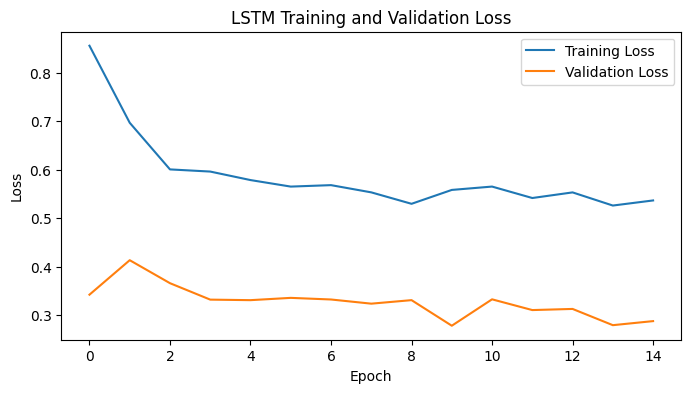

In [30]:
# Plot training and validation loss

plt.figure(
    figsize=(8,4)
)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "LSTM Training and Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [31]:
# Generate LSTM prediction for all available sequences

all_sequences = np.stack(
    sequence_df["Sequence"].values
)

all_flat = (
    all_sequences
    .reshape(-1, n_features)
)

all_scaled = (
    scaler
    .transform(all_flat)
    .reshape(
        all_sequences.shape[0],
        sequence_length,
        n_features
    )
)

sequence_df[
    "LSTM_News_Risk_Probability"
] = (
    model
    .predict(
        all_scaled,
        verbose=0
    )
    .ravel()
)

display(
    sequence_df[
        [
            "Supplier_ID",
            "Date",
            "LSTM_News_Risk_Probability"
        ]
    ].head()
)

,Supplier_ID,Date,LSTM_News_Risk_Probability
0,SUP0101,2023-04-01,0.016844
1,SUP0181,2023-04-01,0.658367
2,SUP0028,2023-04-01,0.001078
3,SUP0174,2023-04-01,0.767814
4,SUP0105,2023-04-01,0.004609


In [32]:
# Select LSTM results

lstm_output = sequence_df[
    [
        "Supplier_ID",
        "Date",
        "LSTM_News_Risk_Probability"
    ]
].copy()


# Merge LSTM results with main dataset

df = df.merge(

    lstm_output,

    on=[
        "Supplier_ID",
        "Date"
    ],

    how="left"
)


# For records without a complete 90-day sequence,
# use FinBERT negative probability.

df[
    "News_Risk_Probability"
] = df[
    "LSTM_News_Risk_Probability"
].fillna(
    df[
        "FinBERT_News_Risk_Probability"
    ]
)


display(
    df[
        [
            "Supplier_ID",
            "Date",
            "FinBERT_News_Risk_Probability",
            "LSTM_News_Risk_Probability",
            "News_Risk_Probability"
        ]
    ].head(10)
)

,Supplier_ID,Date,FinBERT_News_Risk_Probability,LSTM_News_Risk_Probability,News_Risk_Probability
0,SUP0002,2023-01-01,0.035035,NaN,0.035035
1,SUP0008,2023-01-01,0.019845,NaN,0.019845
2,SUP0009,2023-01-01,0.024861,NaN,0.024861
3,SUP0010,2023-01-01,0.019845,NaN,0.019845
4,SUP0018,2023-01-01,0.051384,NaN,0.051384
5,SUP0022,2023-01-01,0.024861,NaN,0.024861
6,SUP0023,2023-01-01,0.930249,NaN,0.930249
7,SUP0024,2023-01-01,0.930249,NaN,0.930249
8,SUP0032,2023-01-01,0.973419,NaN,0.973419
9,SUP0040,2023-01-01,0.017252,NaN,0.017252


In [33]:
# Combine financial risk and news risk.
#
# 60% -> XGBoost financial risk
# 40% -> FinBERT/LSTM news risk

df[
    "Final_Risk_Score"
] = (

    0.60 *
    df[
        "XGBoost_Financial_Risk_Probability"
    ]

    +

    0.40 *
    df[
        "News_Risk_Probability"
    ]
)


# Convert score into risk categories

def risk_category(score):

    if score < 0.33:

        return "Low"

    elif score < 0.66:

        return "Medium"

    else:

        return "High"


df[
    "Risk_Category"
] = df[
    "Final_Risk_Score"
].apply(
    risk_category
)


display(
    df[
        [
            "Supplier_ID",
            "Supplier_Name",
            "Date",
            "XGBoost_Financial_Risk_Probability",
            "News_Risk_Probability",
            "Final_Risk_Score",
            "Risk_Category"
        ]
    ].head(20)
)

,Supplier_ID,Supplier_Name,Date,XGBoost_Financial_Risk_Probability,News_Risk_Probability,Final_Risk_Score,Risk_Category
0,SUP0002,Supplier_0002,2023-01-01,0.042213,0.035035,0.039342,Low
1,SUP0008,Supplier_0008,2023-01-01,0.002468,0.019845,0.009419,Low
2,SUP0009,Supplier_0009,2023-01-01,0.006617,0.024861,0.013915,Low
3,SUP0010,Supplier_0010,2023-01-01,0.003634,0.019845,0.010118,Low
4,SUP0018,Supplier_0018,2023-01-01,0.003038,0.051384,0.022376,Low
5,SUP0022,Supplier_0022,2023-01-01,0.000547,0.024861,0.010272,Low
6,SUP0023,Supplier_0023,2023-01-01,0.002754,0.930249,0.373752,Medium
7,SUP0024,Supplier_0024,2023-01-01,0.986258,0.930249,0.963855,High
8,SUP0032,Supplier_0032,2023-01-01,0.004166,0.973419,0.391867,Medium
9,SUP0040,Supplier_0040,2023-01-01,0.002339,0.017252,0.008304,Low


Risk_Category
Low       7999
Medium    1607
High       374
Name: count, dtype: int64


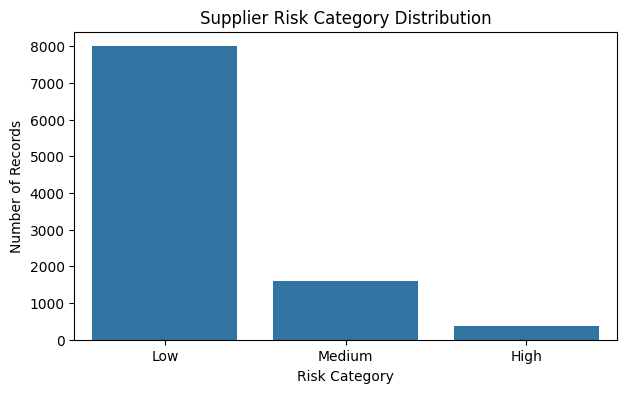

In [34]:
# Count Low, Medium and High risk suppliers/records

print(
    df[
        "Risk_Category"
    ].value_counts()
)

# Plot risk distribution

plt.figure(
    figsize=(7,4)
)

sns.countplot(
    x="Risk_Category",
    data=df
)

plt.title(
    "Supplier Risk Category Distribution"
)

plt.xlabel(
    "Risk Category"
)

plt.ylabel(
    "Number of Records"
)

plt.show()

In [35]:
# Create one summary table for each supplier

supplier_summary = (

    df.groupby(
        [
            "Supplier_ID",
            "Supplier_Name",
            "Industry",
            "Country"
        ],
        as_index=False
    )

    .agg(

        Average_Financial_Risk=(
            "XGBoost_Financial_Risk_Probability",
            "mean"
        ),

        Average_News_Risk=(
            "News_Risk_Probability",
            "mean"
        ),

        Average_Final_Risk=(
            "Final_Risk_Score",
            "mean"
        ),

        Maximum_Final_Risk=(
            "Final_Risk_Score",
            "max"
        ),

        Negative_News_Average=(
            "FinBERT_Negative_Probability",
            "mean"
        ),

        Records=(
            "Supplier_ID",
            "size"
        )
    )
)


# Assign supplier-level risk category

supplier_summary[
    "Risk_Category"
] = supplier_summary[
    "Average_Final_Risk"
].apply(
    risk_category
)


display(
    supplier_summary.head(20)
)

,Supplier_ID,Supplier_Name,Industry,Country,Average_Financial_Risk,Average_News_Risk,Average_Final_Risk,Maximum_Final_Risk,Negative_News_Average,Records,Risk_Category
0,SUP0001,Supplier_0001,Machinery,France,0.078486,0.215114,0.133137,0.672272,0.303549,40,Low
1,SUP0002,Supplier_0002,Chemicals,Japan,0.035673,0.080271,0.053512,0.381532,0.141902,40,Low
2,SUP0003,Supplier_0003,Construction,Singapore,0.052817,0.185649,0.105950,0.561901,0.279995,40,Low
3,SUP0004,Supplier_0004,Textiles,France,0.145057,0.346978,0.225825,0.952231,0.419905,40,Low
4,SUP0005,Supplier_0005,Machinery,Japan,0.115378,0.208300,0.152547,0.647002,0.288684,39,Low
5,SUP0006,Supplier_0006,Consumer Goods,Singapore,0.088037,0.180796,0.125140,0.505791,0.259299,40,Low
6,SUP0007,Supplier_0007,Pharmaceuticals,Germany,0.252056,0.437443,0.326211,0.940554,0.516526,40,Low
7,SUP0008,Supplier_0008,Machinery,France,0.096951,0.138229,0.113462,0.547295,0.187841,40,Low
8,SUP0009,Supplier_0009,Construction,Singapore,0.086104,0.199012,0.131267,0.638103,0.282262,40,Low
9,SUP0010,Supplier_0010,Textiles,India,0.260654,0.267529,0.263404,0.963957,0.349909,40,Low


In [36]:
# Display final dataset size

print(
    "FINAL DATASET SHAPE:"
)

print(
    df.shape
)


# Check missing values

print(
    "\nRemaining Missing Values:"
)

display(
    df.isnull()
    .sum()
    .sort_values(
        ascending=False
    )
    .head(20)
)


# Check duplicate rows

print(
    "\nDuplicate Rows:"
)

print(
    df.duplicated().sum()
)


# Risk categories

print(
    "\nRisk Categories:"
)

display(
    df[
        "Risk_Category"
    ].value_counts()
)


# Final columns

print(
    "\nFinal Columns:"
)

print(
    df.columns.tolist()
)

FINAL DATASET SHAPE:
(9980, 31)

Remaining Missing Values:


,0
LSTM_News_Risk_Probability,2560
Supplier_Name,0
Supplier_ID,0
Country,0
Date,0
Revenue_Million_USD,0
Industry,0
Assets_Million_USD,0
Current_Assets_Million_USD,0
Current_Liabilities_Million_USD,0



Duplicate Rows:
0

Risk Categories:


,count
Risk_Category,
Low,7999
Medium,1607
High,374



Final Columns:
['Supplier_ID', 'Supplier_Name', 'Industry', 'Country', 'Date', 'Revenue_Million_USD', 'Debt_Million_USD', 'Assets_Million_USD', 'Current_Assets_Million_USD', 'Current_Liabilities_Million_USD', 'Leverage', 'Current_Ratio', 'Financial_Stability_ZScore', 'Profit_Margin', 'Cash_Flow_Million_USD', 'News_Headline', 'News_Text', 'Synthetic_News_Sentiment', 'Disruption_Within_90_Days', 'News_Combined', 'Financial_Stress_Index', 'XGBoost_Financial_Risk_Probability', 'FinBERT_Positive_Probability', 'FinBERT_Negative_Probability', 'FinBERT_Neutral_Probability', 'FinBERT_Sentiment_Score', 'FinBERT_News_Risk_Probability', 'LSTM_News_Risk_Probability', 'News_Risk_Probability', 'Final_Risk_Score', 'Risk_Category']


In [37]:
# Name of final processed Excel file

processed_file = (
    "supplier_risk_processed_with_xgboost_finbert_lstm.xlsx"
)


# Save two sheets:
# 1. Complete processed dataset
# 2. Supplier-level summary

with pd.ExcelWriter(
    processed_file,
    engine="openpyxl"
) as writer:

    df.to_excel(
        writer,
        sheet_name="Processed_Data",
        index=False
    )

    supplier_summary.to_excel(
        writer,
        sheet_name="Supplier_Summary",
        index=False
    )


print(
    "Processed dataset saved successfully:"
)

print(
    processed_file
)

Processed dataset saved successfully:
supplier_risk_processed_with_xgboost_finbert_lstm.xlsx


In [38]:
# Save complete processed data as CSV

processed_csv = (
    "supplier_risk_processed.csv"
)

df.to_csv(
    processed_csv,
    index=False
)


# Save supplier summary as CSV

summary_csv = (
    "supplier_risk_supplier_summary.csv"
)

supplier_summary.to_csv(
    summary_csv,
    index=False
)


print(
    "CSV files created successfully"
)

CSV files created successfully


In [39]:
# Download the complete processed Excel dataset

files.download(
    "supplier_risk_processed_with_xgboost_finbert_lstm.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>